# Magnetic particle transport — PINN literature validation

**An actual trained time-input PINN.** The trajectories plotted below are predictions of trained neural networks, compared after training with the published analytical relation. No trajectory data or analytical solution is used as a training target.

Reference: E. P. Furlani & K. C. Ng, *Physical Review E* **73**, 061919 (2006). [DOI](https://doi.org/10.1103/PhysRevE.73.061919) · [Author full text](https://www.photonics.buffalo.edu/docs/Analytical%20Analysis%20of%20Magnetic%20Nanoparticle%20Transport%20in%20Microvasculature.pdf). Conditions of Fig. 8(a,b), Eqs. (53), (56)–(59).

**Scope:** this is the reduced, prescribed-flow **one-way theoretical benchmark** from the paper. It validates the PINN magnetic particle-transport component. It does not validate full two-way CFD, a magnetic controller, or experiments. The former direct numerical channel demonstration is not included in this validation-only notebook.

Run all cells in order. CPU or CUDA is selected automatically. This file is self-contained; no companion Python files are needed.

In [1]:
import importlib.util
required = ['torch', 'numpy', 'scipy', 'matplotlib', 'PIL', 'IPython']
missing = [m for m in required if importlib.util.find_spec(m) is None]
if missing:
    raise ImportError('Install dependencies first: %pip install torch numpy scipy matplotlib pillow ipython; then restart and Run all. Missing: ' + ', '.join(missing))


## Physical model, coordinates and network

The axial coordinate is $z$ and the transverse coordinate $x$ is negative toward the magnet. Define
$$d=(1+\beta)R_{mag},\quad X=x/R_v,\quad Z=z/d,\quad \tau=2\bar v_f t/d.$$
The particle is overdamped. Stokes drag balances the induced-dipole force; the paper neglects axial magnetic drift and uses $R_v/d\ll1$ for its reduced solution:
$$\mathbf F_m={\alpha\over2}\nabla B^2,\quad \alpha={3V_p\over\mu_0},\quad 6\pi\eta R_p\dot x=F_{m,x},\quad \dot z=2\bar v_f[1-(x/R_v)^2].$$
Thus the **trained equations** are
$$r_x={dX_\theta\over d\tau}+{C\over(1+Z_\theta^2)^3}=0,\qquad
r_z={dZ_\theta\over d\tau}-(1-X_\theta^2)=0,$$
$$C={\mu_0 R_p^2(3)M_s^2\over18\eta R_v\bar v_f(1+\beta)^4}.$$

Each case has an independent network: **local time $s\in[0,1]$ → two coordinates $(X,Z)$**. Two hidden layers of 24 tanh units; float64; Adam followed by L-BFGS. The physical interval is $\tau=\tau_k+\Delta\tau s$.

Hard initial conditions: $\mathbf q_\theta(s)=\mathbf q_k+\Delta\tau\,s\,N_\theta(s)$. Training minimizes $\mathcal L=\langle r_x^2+r_z^2\rangle$ using automatic differentiation. After each time slab, its predicted final state initializes the next slab. **No numerical ODE integrator supplies these states.** First wall capture $X=-1$ or axial exit $z/R_{mag}=4$ terminates a case; scalar root finding is applied only to network outputs.

The ten configurations are trained independently (vectorized for speed), not as a model that interpolates particle radius or magnet distance. Since flow is prescribed by the benchmark, there is no fluid network in this notebook.

In [2]:
"""Time-input, data-free PINN benchmark: Furlani & Ng, PRE 73 061919 (2006).
Training uses ONLY ODE residuals and initial conditions. No reference trajectory,
numerical ODE solver, or analytic trajectory is called by train().
"""
import os, json, time, math
from pathlib import Path
import numpy as np
import torch
from torch import nn

DOI='10.1103/PhysRevE.73.061919'

def parameters():
    mu0=4*np.pi*1e-7; Ms=1e6; Rmag=.02; Rv=75e-6; mean=.015
    D=2*Rv*1e6; HD=.45; plasma=.0012
    eta045=6*np.exp(-.085*D)+3.2-2.44*np.exp(-.06*D**.645)
    cc=(.8+np.exp(-.075*D))*(1/(1+1e-11*D**12)-1)+1/(1+1e-11*D**12)
    eta=plasma*(1+(eta045-1)*((1-HD)**cc-1)/((1-.45)**cc-1)*(D/(D-1.1))**2)*(D/(D-1.1))**2
    beta=np.repeat([1.,1.25],5); rp=np.tile(np.arange(400,601,50),2)*1e-9
    d=(1+beta)*Rmag
    C=mu0*rp**2*3*Ms**2/(18*eta*Rv*mean*(1+beta)**4)
    return dict(mu0=mu0,Ms=Ms,Rmag=Rmag,Rv=Rv,mean=mean,eta=eta,beta=beta,rp=rp,d=d,C=C,
                z0=-4/(1+beta),zend=4/(1+beta))

# Each of the 10 trajectories has its own weights. Vectorization is only for speed.
class ParallelPINN(nn.Module):
    def __init__(self,q0,slab,width=24):
        super().__init__(); self.register_buffer('q0',q0.clone()); self.slab=slab
        sizes=[1,width,width,2];self.weights=nn.ParameterList();self.biases=nn.ParameterList()
        for a,b in zip(sizes[:-1],sizes[1:]):
            self.weights.append(nn.Parameter(torch.randn(10,a,b,device=q0.device,dtype=q0.dtype)*math.sqrt(2/(a+b))))
            self.biases.append(nn.Parameter(torch.zeros(10,1,b,device=q0.device,dtype=q0.dtype)))
    def forward(self,s): # s shape [case, point, 1]; each case independent
        h=2*s-1
        for j,(w,b) in enumerate(zip(self.weights,self.biases)):
            h=torch.bmm(h,w)+b
            if j<len(self.weights)-1:h=torch.tanh(h)
        return self.q0[:,None,:]+self.slab*s*h # hard initial condition

def residual(model,s,C):
    q=model(s);X=q[...,0:1];Z=q[...,1:2]
    dx=torch.autograd.grad(X.sum(),s,create_graph=True)[0]/model.slab
    dz=torch.autograd.grad(Z.sum(),s,create_graph=True)[0]/model.slab
    # Induced-dipole magnetic force / Stokes drag, reduced Eqs.56-57.
    return torch.cat((dx+C[:,None,None]/(1+Z*Z)**3,dz-(1-X*X)),dim=-1)

def train(out='pinn_results',seed=42,slab=.5,adam_steps=200,lbfgs_steps=800,
          collocation=129,max_slabs=40,device=None):
    """No analytic/reference data allowed here. Time marching transfers PINN states only."""
    out=Path(out);out.mkdir(parents=True,exist_ok=True)
    torch.set_num_threads(1);torch.manual_seed(seed)
    device=device or ('cuda' if torch.cuda.is_available() else 'cpu')
    dtype=torch.float64;p=parameters();C=torch.tensor(p['C'],device=device,dtype=dtype)
    q0=torch.tensor(np.column_stack((np.zeros(10),p['z0'])),device=device,dtype=dtype)
    active=np.ones(10,dtype=bool);paths=[[] for _ in range(10)];events=[None]*10
    from scipy.optimize import brentq # scalar roots on PINN outputs only; NOT ODE integration
    history=[];tic=time.perf_counter()
    for seg in range(max_slabs):
        model=ParallelPINN(q0,slab).to(device)
        # Fixed collocation only, unrelated to validation coordinates.
        s=torch.linspace(0,1,collocation,device=device,dtype=dtype)[None,:,None].repeat(10,1,1).requires_grad_(True)
        mask=torch.tensor(active,device=device,dtype=dtype)[:,None,None]
        def loss():
            r=residual(model,s,C)
            return (r*r*mask).sum()/(mask.sum()*collocation*2)
        opt=torch.optim.Adam(model.parameters(),lr=.003)
        for _ in range(adam_steps):
            opt.zero_grad();l=loss();l.backward();opt.step()
        opt=torch.optim.LBFGS(model.parameters(),lr=1.,max_iter=lbfgs_steps,
              tolerance_grad=1e-11,tolerance_change=1e-14,line_search_fn='strong_wolfe',history_size=40)
        def closure():
            opt.zero_grad();l=loss();l.backward();return l
        opt.step(closure)
        # Disjoint dense residual audit; no analytic trajectory used.
        sa=((torch.arange(193,device=device,dtype=dtype)+.37)/193)[None,:,None].repeat(10,1,1).requires_grad_(True)
        rr=residual(model,sa,C).detach().cpu().numpy()
        rms=float(np.sqrt(np.mean(rr[active]**2)))
        history.append(dict(segment=seg,tau_start=seg*slab,loss=float(loss().detach()),heldout_residual_rms=rms))
        grid=np.linspace(0,1,201)
        def evaluate(ss):
            with torch.no_grad():
                st=torch.tensor(np.atleast_1d(ss),device=device,dtype=dtype)[None,:,None].repeat(10,1,1)
                return model(st).cpu().numpy()
        pred=evaluate(grid)
        for i in np.where(active)[0]:
            gcap=pred[i,:,0]+1;gexit=p['zend'][i]-pred[i,:,1]
            cand=[]
            for name,g,col,target in [('capture',gcap,0,-1.),('exit',gexit,1,p['zend'][i])]:
                crossings=np.where(g<=0)[0]
                if len(crossings):
                    k=int(crossings[0]);root=brentq(lambda a:evaluate(a)[i,0,col]-target,grid[max(k-1,0)],grid[k],xtol=1e-13)
                    cand.append((root,name))
            end,ename=min(cand) if cand else (1.,None)
            sg=np.linspace(0,end,101);qq=evaluate(sg)[i]
            piece=np.column_stack(((seg+sg)*slab,qq))
            paths[i].extend(piece if seg==0 else piece[1:])
            if ename:
                active[i]=False;events[i]=ename
        torch.save({'state_dict':model.state_dict(),'slab':slab,'width':24,'tau_start':seg*slab},out/f'segment_{seg:02d}.pt')
        with torch.no_grad():
            nxt=model(torch.ones((10,1,1),device=device,dtype=dtype))[:,0,:]
            q0=torch.where(torch.tensor(active,device=device)[:,None],nxt,q0).detach()
        print(f'Slab {seg+1}: held-out residual RMS={rms:.2e}; active={active.sum()}',flush=True)
        if not active.any():break
    if active.any():raise RuntimeError('Some particles did not terminate. Increase max_slabs; do not report a pass.')
    for i,pa in enumerate(paths):
        np.savetxt(out/f'case_{i:02d}.csv',pa,delimiter=',',header='tau,X_PINN,Z_PINN',comments='')
    run=dict(seed=seed,device=device,dtype='float64',seconds=time.perf_counter()-tic,events=events,history=history,
      settings=dict(slab=slab,adam_steps=adam_steps,lbfgs_steps=lbfgs_steps,collocation=collocation,max_slabs=max_slabs),
      training_data='ODE residuals + hard initial conditions only; no analytical trajectories, no solve_ivp, no fitted physical parameters')
    (out/'training.json').write_text(json.dumps(run,indent=2))
    return run

# Reference evaluation is deliberately isolated and runs only after train() finishes.
def validate(out='pinn_results'):
    from scipy.optimize import brentq
    import matplotlib.pyplot as plt
    from matplotlib.lines import Line2D
    out=Path(out);p=parameters();run=json.loads((out/'training.json').read_text())
    def I(z):return 3*np.arctan(z)/8+z*(3*z*z+5)/(8*(1+z*z)**2)
    def inverse_h(y):return brentq(lambda x:x-x*x*x/3-y,-1,0,xtol=1e-14)
    rows=[];arrays=[];fig,axs=plt.subplots(1,2,figsize=(12,4.8),layout='constrained')
    ef,ea=plt.subplots(figsize=(10,4),layout='constrained');colors=plt.cm.viridis(np.linspace(.05,.9,5))
    for i in range(10):
        tau,X,Z=np.loadtxt(out/f'case_{i:02d}.csv',delimiter=',',skiprows=1).T
        h=-p['C'][i]*(I(Z)-I(p['z0'][i]))
        ok=(h>=-2/3)&(h<=0)&(abs(X)<.98)
        ref=np.array([inverse_h(v) for v in h[ok]]);err=abs(X[ok]-ref)
        capref=p['C'][i]*(I(p['zend'][i])-I(p['z0'][i]))>=2/3
        zr=brentq(lambda z:p['C'][i]*(I(z)-I(p['z0'][i]))-2/3,p['z0'][i],p['zend'][i]) if capref else None
        row=dict(beta=float(p['beta'][i]),radius_nm=float(p['rp'][i]*1e9),max_error_Rv=float(err.max()),
          rms_error_Rv=float(np.sqrt(np.mean(err**2))),pinn_captured=run['events'][i]=='capture',reference_captured=bool(capref),
          capture_location_error_Rmag=float(abs(Z[-1]-zr)*(1+p['beta'][i])) if capref and run['events'][i]=='capture' else None,
          initial_error=float(max(abs(X[0]),abs(Z[0]-p['z0'][i]))))
        rows.append(row);arrays.append((tau,X,Z))
        zend=zr if capref else p['zend'][i];zg=np.linspace(p['z0'][i],zend,450)
        xr=np.array([inverse_h(np.clip(-p['C'][i]*(I(z)-I(p['z0'][i])),-2/3,0)) for z in zg])
        ax=axs[i//5];co=colors[i%5]
        ax.plot(zg*(1+p['beta'][i]),-xr,color=co,lw=2,label=f'{p["rp"][i]*1e9:.0f} nm')
        ix=np.linspace(0,len(Z)-1,36).astype(int)
        ax.plot(Z[ix]*(1+p['beta'][i]),-X[ix],ls='none',marker='o',mfc='white',mec=co,ms=3.5)
        ea.semilogy(Z[ok]*(1+p['beta'][i]),np.maximum(err,1e-12),color=co,ls='-' if i<5 else '--',label=f'β={p["beta"][i]:g}, {p["rp"][i]*1e9:.0f} nm')
        np.savetxt(out/f'comparison_{i:02d}.csv',np.column_stack((Z[ok]*(1+p['beta'][i]),X[ok],ref,err)),delimiter=',',header='z_Rmag,X_PINN,X_analytic,abs_error_Rv',comments='')
    for ax,b in zip(axs,[1.,1.25]):
        ax.set(title=f'β = {b:g}',xlabel='z / Rmag',ylabel='|x| / Rv',xlim=(-4,4),ylim=(0,1.03));ax.grid(alpha=.2);ax.legend(fontsize=8)
    fig.suptitle('Time-input PINN vs Furlani & Ng (2006), Fig. 8 / Eq. 59')
    fig.legend(handles=[Line2D([0],[0],c='gray',label='Published analytical relation'),Line2D([0],[0],ls='none',marker='o',mfc='white',mec='gray',label='PINN prediction')],loc='outside lower center',ncol=2)
    fig.savefig(out/'pinn_overlay.png',dpi=190);plt.close(fig)
    ea.set(xlabel='z / Rmag',ylabel='Absolute transverse error / Rv',title='Held-out trajectory comparison (|X| < 0.98)');ea.grid(alpha=.2);ea.legend(ncol=2,fontsize=7);ef.tight_layout();ef.savefig(out/'pinn_error.png',dpi=170);plt.close(ef)
    lf,la=plt.subplots(figsize=(8,3.5),layout='constrained')
    la.semilogy([r['segment']+1 for r in run['history']],[r['heldout_residual_rms'] for r in run['history']],'o-');la.set(xlabel='Time slab',ylabel='Residual RMS',title='Physics residual at unseen time points');la.grid(alpha=.2);lf.savefig(out/'pinn_residual.png',dpi=170);plt.close(lf)
    checks=dict(all_events_match=all(r['pinn_captured']==r['reference_captured'] for r in rows),
       max_path_error_below_0_005_Rv=max(r['max_error_Rv'] for r in rows)<.005,
       capture_position_below_0_01_Rmag=all(r['capture_location_error_Rmag']<.01 for r in rows if r['capture_location_error_Rmag'] is not None),
       hard_initial_condition=max(r['initial_error'] for r in rows)<1e-12,
       heldout_residual_below_0_001=max(r['heldout_residual_rms'] for r in run['history'])<.001,
       no_saturation=float(np.max(p['Ms']*p['Rmag']**2/(2*p['d']**2)/(4.78e5/3)))<1.)
    report=dict(doi=DOI,results=rows,checks=checks,all_passed=all(checks.values()),seconds=run['seconds'],device=run['device'],
      max_path_error_Rv=max(r['max_error_Rv'] for r in rows),
      scope='PINN validation of reduced magnetic particle transport only. Prescribed one-way flow; NOT full two-way CFD, controller or experimental validation.')
    (out/'validation.json').write_text(json.dumps(report,indent=2));print(json.dumps(report,indent=2))
    return report



def predict(case_index,t_seconds,out='pinn_results',device='cpu'):
    """Evaluate saved trained networks at physical times. Returns physical x,z in m.
    Valid only up to first predicted wall capture / axial exit. No ODE solver.
    """
    out=Path(out);p=parameters();i=int(case_index)
    if i not in range(10):raise ValueError('case_index must be 0..9')
    tt=np.atleast_1d(t_seconds).astype(float);tau=2*p['mean']*tt/p['d'][i]
    path=np.loadtxt(out/f'case_{i:02d}.csv',delimiter=',',skiprows=1)
    if np.any(tau<0) or np.any(tau>path[-1,0]+1e-10):raise ValueError('Time outside pre-event interval')
    result=np.empty((len(tt),2))
    meta=json.loads((out/'training.json').read_text());slab=meta['settings']['slab'];n=len(meta['history'])
    for j in np.unique(np.minimum((tau/slab).astype(int),n-1)):
        use=np.minimum((tau/slab).astype(int),n-1)==j
        ck=torch.load(out/f'segment_{j:02d}.pt',map_location=device,weights_only=True)
        model=ParallelPINN(ck['state_dict']['q0'],ck['slab'],ck['width']).to(device)
        model.load_state_dict(ck['state_dict']);model.eval()
        s=torch.tensor((tau[use]-ck['tau_start'])/slab,dtype=torch.float64,device=device)[None,:,None].repeat(10,1,1)
        with torch.no_grad():q=model(s)[i].cpu().numpy()
        result[use]=q*np.array([p['Rv'],p['d'][i]])
    return result


def additional_checks(out='pinn_results'):
    """SI force reduction + automatic derivative + saved-model inference audits."""
    out=Path(out);p=parameters();max_force_error=0.;max_reload_error=0.
    mu0=p['mu0']
    for i in range(10):
        d=p['d'][i];rp=p['rp'][i];Vp=4*np.pi*rp**3/3;alpha=3*Vp/mu0
        for Z in np.linspace(-2,2,19):
            z=Z*d;r2=d*d+z*z;a=p['Ms']*p['Rmag']**2
            B=mu0*np.array([a*(d*d-z*z)/(2*r2*r2),a*d*z/r2**2])
            G=mu0*a/r2**3*np.array([[d*(3*z*z-d*d),z*(z*z-3*d*d)],[z*(z*z-3*d*d),d*(d*d-3*z*z)]])
            F=alpha*np.einsum('ij,i->j',G,B)
            reduced=F[0]/(6*np.pi*p['eta']*rp)*d/(2*p['mean']*p['Rv'])
            target=-p['C'][i]/(1+Z*Z)**3
            max_force_error=max(max_force_error,abs(reduced-target)/max(abs(target),1e-30))
        pa=np.loadtxt(out/f'case_{i:02d}.csv',delimiter=',',skiprows=1)
        ids=np.linspace(0,len(pa)-1,7).astype(int)
        q=predict(i,pa[ids,0]*d/(2*p['mean']),out)/np.array([p['Rv'],d])
        max_reload_error=max(max_reload_error,float(np.max(abs(q-pa[ids,1:]))))
    ck=torch.load(out/'segment_00.pt',map_location='cpu',weights_only=True)
    model=ParallelPINN(ck['state_dict']['q0'],ck['slab'],ck['width']);model.load_state_dict(ck['state_dict'])
    s=torch.full((10,1,1),.431,dtype=torch.float64,requires_grad=True);q=model(s)
    ad=torch.autograd.grad(q[...,0].sum(),s)[0].detach().numpy()[...,0]
    with torch.no_grad():fd=((model(s+1e-5)-model(s-1e-5))/(2e-5)).numpy()[...,0]
    derr=float(np.max(abs(ad-fd)))
    extra=dict(SI_dipole_force_matches_PINN_rhs=bool(max_force_error<1e-12),
               checkpoint_predictions_match_saved_paths=max_reload_error<1e-10,
               autodiff_matches_finite_difference=derr<1e-8)
    report=json.loads((out/'validation.json').read_text());report['checks'].update(extra)
    report['all_passed']=all(report['checks'].values())
    report['audit_errors']=dict(force_relative=max_force_error,reloaded_coordinates=max_reload_error,AD_absolute=derr)
    (out/'validation.json').write_text(json.dumps(report,indent=2))
    print(json.dumps(extra,indent=2))
    return report



## Published parameters and training settings

Magnet radius 20 mm; vessel radius 75 µm; mean flow 15 mm/s; magnet magnetization $10^6$ A/m; particle saturation magnetization $4.78\times10^5$ A/m. Effective viscosity follows the paper's hematocrit correction at 0.45 (implemented with both diameter correction factors). Particle radii: 400, 450, 500, 550, 600 nm; $\beta=1,1.25$. Initial $x=0$, $z/R_{mag}=-4$.

Seeds are fixed. CUDA and CPU may follow slightly different optimizer paths; inspect the checks rather than assuming a guaranteed pass or runtime.

In [3]:
OUT = Path('pinn_validation_results')
SETTINGS = dict(seed=42, slab=0.5, adam_steps=200, lbfgs_steps=800,
                collocation=129, max_slabs=40)
p = parameters()
print('Effective viscosity:', p['eta'], 'Pa s')
print('Device:', 'cuda' if torch.cuda.is_available() else 'cpu')
training_run = train(OUT, **SETTINGS)
print('Training seconds:', round(training_run['seconds'], 2))

Effective viscosity: 0.003276913272013514 Pa s
Device: cpu
Slab 1: held-out residual RMS=2.17e-04; active=10
Slab 2: held-out residual RMS=2.46e-04; active=10
Slab 3: held-out residual RMS=2.66e-04; active=10
Slab 4: held-out residual RMS=2.23e-04; active=10
Slab 5: held-out residual RMS=5.90e-04; active=8
Slab 6: held-out residual RMS=2.25e-04; active=5
Slab 7: held-out residual RMS=2.28e-04; active=4
Slab 8: held-out residual RMS=3.20e-04; active=3
Slab 9: held-out residual RMS=1.30e-04; active=2
Slab 10: held-out residual RMS=1.94e-04; active=2
Slab 11: held-out residual RMS=1.43e-04; active=2
Slab 12: held-out residual RMS=5.00e-05; active=2
Slab 13: held-out residual RMS=1.23e-04; active=1
Slab 14: held-out residual RMS=6.01e-05; active=1
Slab 15: held-out residual RMS=1.63e-04; active=1
Slab 16: held-out residual RMS=1.01e-04; active=1
Slab 17: held-out residual RMS=2.90e-04; active=1
Slab 18: held-out residual RMS=1.69e-04; active=1
Slab 19: held-out residual RMS=2.58e-04; activ

## Independent comparison after training

The published implicit analytical solution (Eq. 59) is used **only here**:
$$h(X)=-C[I(Z)-I(Z_0)],\quad h(X)=X-X^3/3,$$
$$I(Z)={3\over8}\tan^{-1}Z+{Z(3Z^2+5)\over8(1+Z^2)^2}.$$
Its physical inverse branch is $-1\le X\le0$. Compare trajectory error before $|X|=0.98$ because this spatial inverse becomes singular at the wall; compare capture location separately. Both capture and passage cases are included. No parameters are fitted.

Acceptance criteria are explicit in code: maximum path error $<0.005R_v$; capture-location error $<0.01R_{mag}$; held-out residual RMS $<0.001$; all capture/exit classifications correct; exact initial conditions; unsaturated response. Additional audits check SI force reduction, derivatives, and saved-weight inference. These are numerical acceptance criteria, not claims of experimental accuracy.

/tmp/ipykernel_49/2167795437.py:149: UserWarning: The figure layout has changed to tight
  ea.set(xlabel='z / Rmag',ylabel='Absolute transverse error / Rv',title='Held-out trajectory comparison (|X| < 0.98)');ea.grid(alpha=.2);ea.legend(ncol=2,fontsize=7);ef.tight_layout();ef.savefig(out/'pinn_error.png',dpi=170);plt.close(ef)


{
  "doi": "10.1103/PhysRevE.73.061919",
  "results": [
    {
      "beta": 1.0,
      "radius_nm": 400.00000000000006,
      "max_error_Rv": 5.251355923918677e-05,
      "rms_error_Rv": 2.185691485909018e-05,
      "pinn_captured": false,
      "reference_captured": false,
      "capture_location_error_Rmag": null,
      "initial_error": 0.0
    },
    {
      "beta": 1.0,
      "radius_nm": 450.00000000000006,
      "max_error_Rv": 0.00012060705649052927,
      "rms_error_Rv": 1.9387888785952492e-05,
      "pinn_captured": true,
      "reference_captured": true,
      "capture_location_error_Rmag": 1.7933564213978848e-05,
      "initial_error": 0.0
    },
    {
      "beta": 1.0,
      "radius_nm": 500.00000000000006,
      "max_error_Rv": 0.00025874791208813086,
      "rms_error_Rv": 5.355656696425879e-05,
      "pinn_captured": true,
      "reference_captured": true,
      "capture_location_error_Rmag": 2.3132909774625787e-05,
      "initial_error": 0.0
    },
    {
      "beta": 1

| β | Radius (nm) | Max error / Rv | PINN capture | Reference capture | Capture error / Rmag |
|---|---:|---:|---|---|---:|
| 1.0 | 400 | 5.251e-05 | False | False | — |
| 1.0 | 450 | 1.206e-04 | True | True | 1.793e-05 |
| 1.0 | 500 | 2.587e-04 | True | True | 2.313e-05 |
| 1.0 | 550 | 1.415e-03 | True | True | 9.581e-05 |
| 1.0 | 600 | 1.146e-03 | True | True | 5.865e-05 |
| 1.25 | 400 | 2.938e-05 | False | False | — |
| 1.25 | 450 | 2.866e-05 | False | False | — |
| 1.25 | 500 | 2.801e-05 | False | False | — |
| 1.25 | 550 | 2.175e-04 | True | True | 5.254e-05 |
| 1.25 | 600 | 2.105e-04 | True | True | 3.585e-06 |

Checks: {'all_events_match': True, 'max_path_error_below_0_005_Rv': True, 'capture_position_below_0_01_Rmag': True, 'hard_initial_condition': True, 'heldout_residual_below_0_001': True, 'no_saturation': True, 'SI_dipole_force_matches_PINN_rhs': True, 'checkpoint_predictions_match_saved_paths': True, 'autodiff_matches_finite_difference': True}
All passed: True
Worst trajectory error / Rv: 0.0014147297420625815


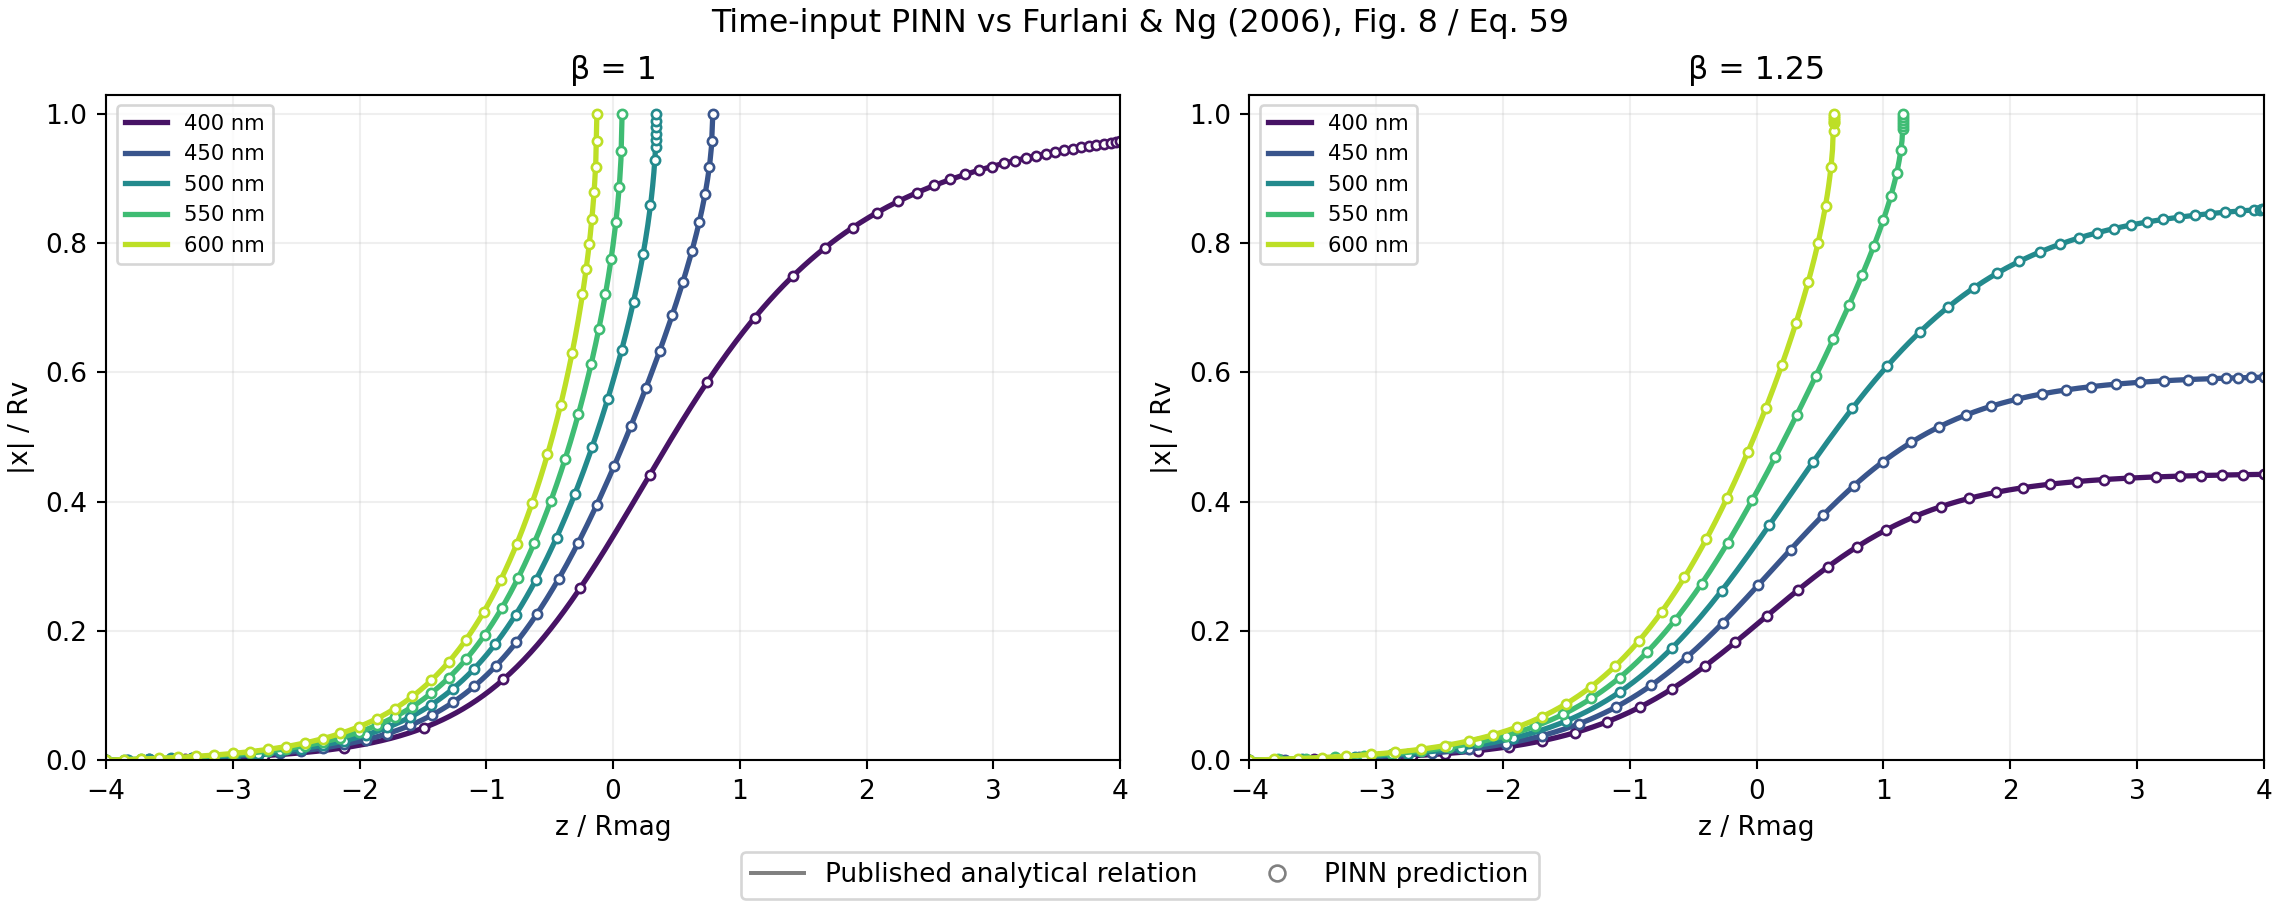

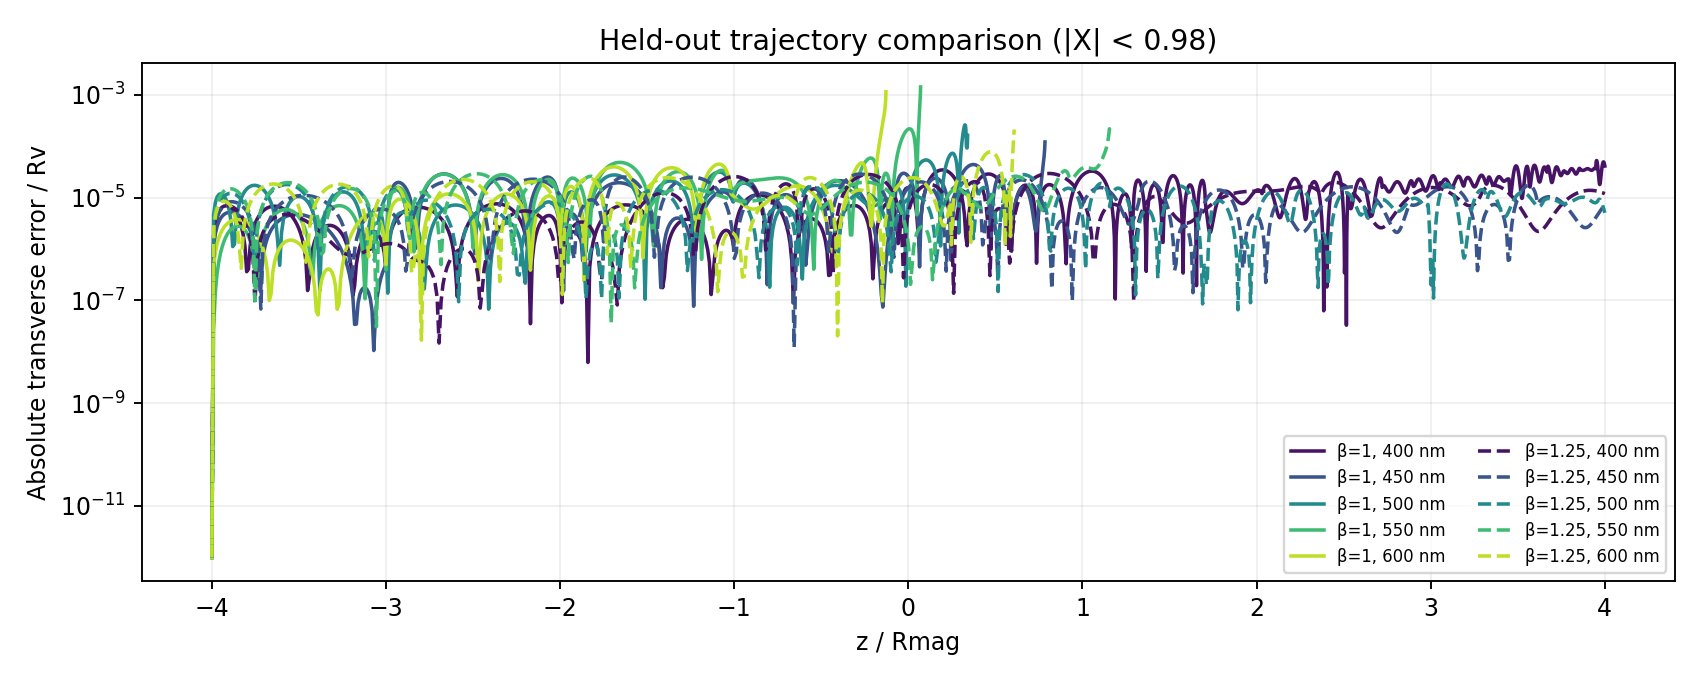

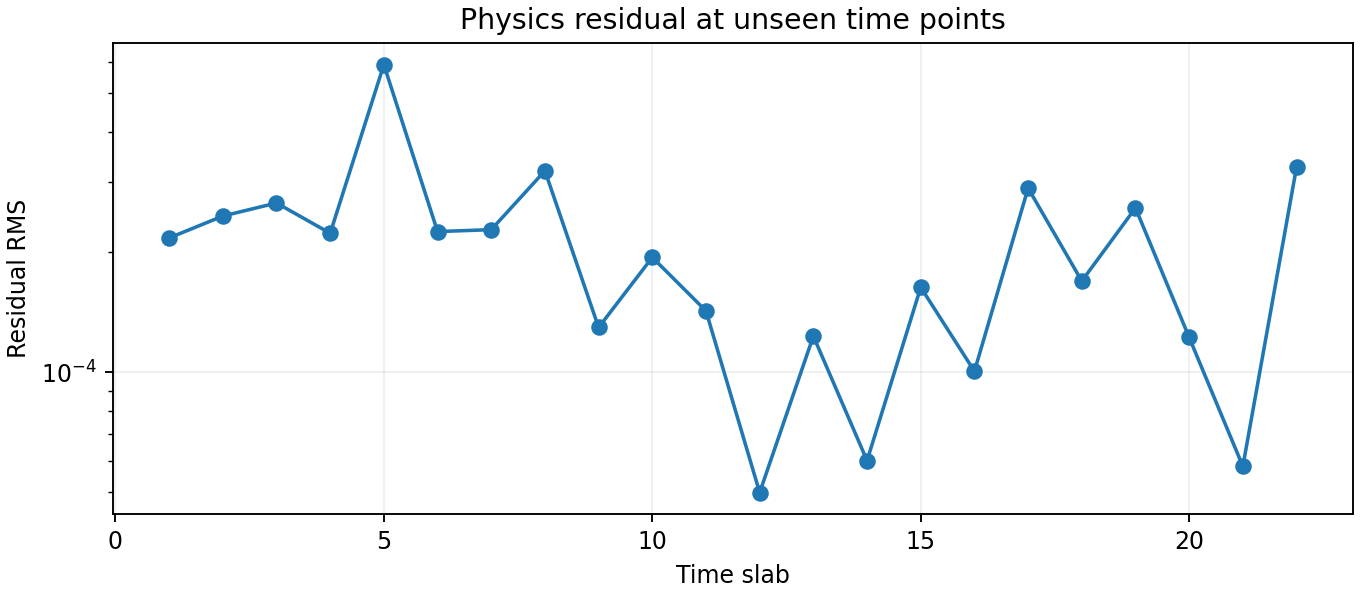

In [4]:
report = validate(OUT)
report = additional_checks(OUT)
from IPython.display import display, Markdown, Image, HTML
header = '| β | Radius (nm) | Max error / Rv | PINN capture | Reference capture | Capture error / Rmag |\n|---|---:|---:|---|---|---:|\n'
rows = []
for r in report['results']:
    ce = r['capture_location_error_Rmag']
    cs = '—' if ce is None else f'{ce:.3e}'
    rows.append(f"| {r['beta']} | {r['radius_nm']:.0f} | {r['max_error_Rv']:.3e} | {r['pinn_captured']} | {r['reference_captured']} | {cs} |")
display(Markdown(header + '\n'.join(rows)))
print('Checks:', report['checks'])
print('All passed:', report['all_passed'])
print('Worst trajectory error / Rv:', report['max_path_error_Rv'])
for name in ['pinn_overlay.png', 'pinn_error.png', 'pinn_residual.png']:
    display(Image(filename=str(OUT/name)))

## Motion from trained PINN predictions

Markers follow the learned trajectories. Each panel is a separate magnet distance. Time below is the dimensionless time $\tau$; its physical time scale differs between panels. A marker stays at its last point after capture or exit; post-event dynamics are not modeled. Animation resampling is only for display and is not part of the solver.


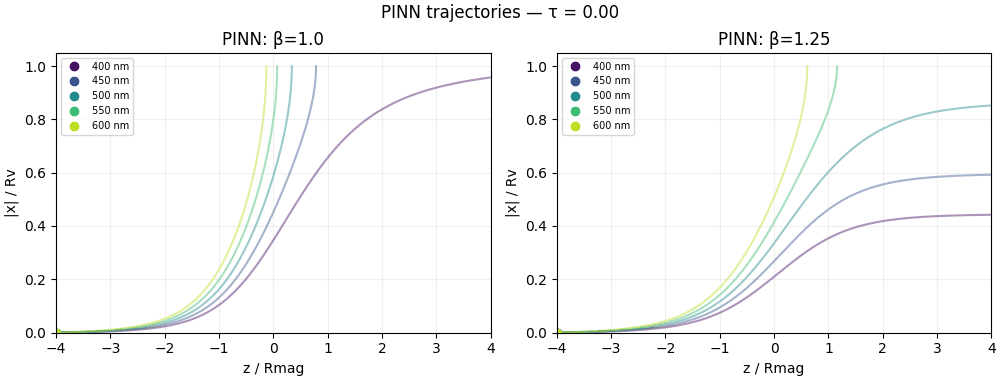

In [5]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
paths = [np.loadtxt(OUT/f'case_{i:02d}.csv', delimiter=',', skiprows=1) for i in range(10)]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout='constrained')
markers=[]
colors=plt.cm.viridis(np.linspace(.05,.9,5))
for i, pa in enumerate(paths):
    ax=axes[i//5]
    ax.plot(pa[:,2]*(1+p['beta'][i]), -pa[:,1], color=colors[i%5], alpha=.45)
    dot,=ax.plot([],[], 'o', color=colors[i%5], label=f"{p['rp'][i]*1e9:.0f} nm")
    markers.append(dot)
for ax,b in zip(axes,[1.,1.25]):
    ax.set(xlim=(-4,4), ylim=(0,1.05), xlabel='z / Rmag', ylabel='|x| / Rv', title=f'PINN: β={b}')
    ax.legend(fontsize=7);ax.grid(alpha=.2)
clock=fig.suptitle('')
times=np.linspace(0,max(pa[-1,0] for pa in paths),90)
def update(k):
    tau=times[k]
    for i,pa in enumerate(paths):
        x=np.interp(tau,pa[:,0],pa[:,1]);z=np.interp(tau,pa[:,0],pa[:,2])
        markers[i].set_data([z*(1+p['beta'][i])],[-x])
    clock.set_text(f'PINN trajectories — τ = {tau:.2f}')
    return markers+[clock]
ani=FuncAnimation(fig,update,frames=len(times),interval=70,blit=False)
ani.save(OUT/'pinn_motion.gif',writer=PillowWriter(fps=14))
plt.close(fig)
import base64
gif64=base64.b64encode((OUT/'pinn_motion.gif').read_bytes()).decode()
display(HTML(f'<img src="data:image/gif;base64,{gif64}" alt="PINN particle trajectories"/>'))

## Evaluate the saved PINN at physical times

`predict` reloads trained weights; it does not integrate an ODE. Input time is seconds, output columns are physical transverse $x$ and axial $z$ in metres. Valid up to the first capture or exit. Checkpoints, CSV trajectories and JSON diagnostics are written to `pinn_validation_results` when running the notebook.

In [6]:
case_index=0  # beta=1, particle radius=400 nm
pa=paths[case_index]
times_s=np.linspace(0,pa[-1,0]*p['d'][case_index]/(2*p['mean']),5)
print('Times [s]:',times_s)
print('PINN [x,z] [m]:\n',predict(case_index,times_s,OUT))
assert report['all_passed'], 'PINN acceptance criteria failed: inspect validation.json before presenting results.'
print('PASS: all numerical validation checks passed.')

Times [s]: [ 0.          3.60429298  7.20858595 10.81287893 14.4171719 ]
PINN [x,z] [m]:
 [[ 0.00000000e+00 -8.00000000e-02]
 [-4.88292494e-05  1.96168054e-02]
 [-6.75273462e-05  5.37268652e-02]
 [-7.05556461e-05  6.94934791e-02]
 [-7.18287926e-05  8.00000000e-02]]
PASS: all numerical validation checks passed.


## Interpretation

This notebook validates a trained particle PINN under the assumptions of Furlani & Ng. It is a theoretical component benchmark with a prescribed cylindrical flow, and **does not demonstrate two-way fluid–particle coupling**. A two-way PINN needs a separately trained fluid network and the drag-reaction source in its fluid momentum residual. No success on this benchmark should be presented as validation of that full coupled problem.

The previous direct-CFD notebook and its numerical checks are separate work; they are not included or relabeled as PINN here.